In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("procurement_kpı_TR.csv")
df.head()

,Siparis_ID,Tedarikci,Siparis_Tarihi,Teslimat_Tarihi,Urun_Kategorisi,Siparis_Durumu,Miktar,Birim_Fiyat,Anlasilan_Fiyat,Kusurlu_Urun_Sayisi,Uyum_Skoru
0,PO-00001,Tedarikçi A,2023-10-17,2023-10-25,Ofis_Malzemeleri,Iptal_Edildi,1176,20.13,17.81,NaN,Uygun
1,PO-00002,Tedarikçi C,2022-04-25,2022-05-05,Ofis_Malzemeleri,Teslim_Edildi,1509,39.32,37.34,235.0,Uygun
2,PO-00003,Tedarikçi E,2022-01-26,2022-02-15,MRO_Bakim_Onarim,Teslim_Edildi,910,95.51,92.26,41.0,Uygun
3,PO-00004,Tedarikçi B,2022-10-09,2022-10-28,Ambalaj_Paketleme,Teslim_Edildi,1344,99.85,95.52,112.0,Uygun
4,PO-00005,Tedarikçi C,2022-09-08,2022-09-20,Hammadde,Teslim_Edildi,1180,64.07,60.53,171.0,Uygun_Degil


# EDA Baslangıcı ve feature engineering

In [11]:
# 1-Sipariş tarihi ve teslim tarihinden toplam kaç günde teslim edildiğini hesaplayıp yeni kolon açalım

In [5]:
# Not: Tarih işlemlerinin doğru çalışması için datetime tipine dönüştürüyoruz
df['Siparis_Tarihi'] = pd.to_datetime(df['Siparis_Tarihi'])
df['Teslimat_Tarihi'] = pd.to_datetime(df['Teslimat_Tarihi'])

# 1. Teslimat Gün Sayısının Hesaplanması
df['Teslimat_Gun_Sayisi'] = (df['Teslimat_Tarihi'] - df['Siparis_Tarihi']).dt.days

In [8]:
#min değer negatif çıakcaktır cunku bos gün var 
df["Teslimat_Gun_Sayisi"].describe()

count    690.000000
mean      10.776812
std        5.729210
min       -5.000000
25%        6.000000
50%       11.000000
75%       16.000000
max       20.000000
Name: Teslimat_Gun_Sayisi, dtype: float64

In [10]:
# 2- Her sipariş için satın alma ve birim fiyatı oranlayıp indirim oranın hesaplanması

In [12]:
df.head()

,Siparis_ID,Tedarikci,Siparis_Tarihi,Teslimat_Tarihi,Urun_Kategorisi,Siparis_Durumu,Miktar,Birim_Fiyat,Anlasilan_Fiyat,Kusurlu_Urun_Sayisi,Uyum_Skoru,Sipariss_Tarihi,Teslimat_Gun_Sayisi
0,PO-00001,Tedarikçi A,2023-10-17,2023-10-25,Ofis_Malzemeleri,Iptal_Edildi,1176,20.13,17.81,NaN,Uygun,2023-10-17,8.0
1,PO-00002,Tedarikçi C,2022-04-25,2022-05-05,Ofis_Malzemeleri,Teslim_Edildi,1509,39.32,37.34,235.0,Uygun,2022-04-25,10.0
2,PO-00003,Tedarikçi E,2022-01-26,2022-02-15,MRO_Bakim_Onarim,Teslim_Edildi,910,95.51,92.26,41.0,Uygun,2022-01-26,20.0
3,PO-00004,Tedarikçi B,2022-10-09,2022-10-28,Ambalaj_Paketleme,Teslim_Edildi,1344,99.85,95.52,112.0,Uygun,2022-10-09,19.0
4,PO-00005,Tedarikçi C,2022-09-08,2022-09-20,Hammadde,Teslim_Edildi,1180,64.07,60.53,171.0,Uygun_Degil,2022-09-08,12.0


In [37]:
df["Indirim_Miktari"] = (df["Birim_Fiyat"] - df["Anlasilan_Fiyat"])
df["Indirim_Orani"] = ((df["Indirim_Miktari"])/ df["Birim_Fiyat"])*100
df[["Indirim_Orani", "Indirim_Miktari"]].describe()

,Indirim_Orani,Indirim_Miktari
count,777.000000,777.000000
mean,7.968088,4.623102
std,4.138690,3.455732
min,1.005414,0.180000
25%,4.279701,1.900000
50%,7.900498,3.650000
75%,11.528384,6.640000
max,14.992548,15.560000


In [38]:
df.head()

,Siparis_ID,Tedarikci,Siparis_Tarihi,Teslimat_Tarihi,Urun_Kategorisi,Siparis_Durumu,Miktar,Birim_Fiyat,Anlasilan_Fiyat,Kusurlu_Urun_Sayisi,Uyum_Skoru,Sipariss_Tarihi,Teslimat_Gun_Sayisi,Indirim Orani,Indirim_Miktari,Basarili_Urun_Orani,Basarili_Urun_Miktari,Indirim_Orani
0,PO-00001,Tedarikçi A,2023-10-17,2023-10-25,Ofis_Malzemeleri,Iptal_Edildi,1176,20.13,17.81,0.0,Uygun,2023-10-17,8.0,11.525087,2.32,1.000000,1176.0,11.525087
1,PO-00002,Tedarikçi C,2022-04-25,2022-05-05,Ofis_Malzemeleri,Teslim_Edildi,1509,39.32,37.34,235.0,Uygun,2022-04-25,10.0,5.035605,1.98,0.844268,1274.0,5.035605
2,PO-00003,Tedarikçi E,2022-01-26,2022-02-15,MRO_Bakim_Onarim,Teslim_Edildi,910,95.51,92.26,41.0,Uygun,2022-01-26,20.0,3.402785,3.25,0.954945,869.0,3.402785
3,PO-00004,Tedarikçi B,2022-10-09,2022-10-28,Ambalaj_Paketleme,Teslim_Edildi,1344,99.85,95.52,112.0,Uygun,2022-10-09,19.0,4.336505,4.33,0.916667,1232.0,4.336505
4,PO-00005,Tedarikçi C,2022-09-08,2022-09-20,Hammadde,Teslim_Edildi,1180,64.07,60.53,171.0,Uygun_Degil,2022-09-08,12.0,5.525207,3.54,0.855085,1009.0,5.525207


In [39]:
# 3- Siparişlerdeki Kusurlu ürün sayısından kusur oranını hesaplayalım

In [40]:
#öncesinde  sutundaki Nan değerleir 0 ile dolduralım

df["Kusurlu_Urun_Sayisi"] = df["Kusurlu_Urun_Sayisi"].fillna(value=0)

In [41]:
df["Basarili_Urun_Miktari"] = df["Miktar"] - df["Kusurlu_Urun_Sayisi"]

df["Basarili_Urun_Orani"] = (df["Basarili_Urun_Miktari"] / df["Miktar"])

df[["Basarili_Urun_Miktari", "Basarili_Urun_Orani"]].describe()

,Basarili_Urun_Miktari,Basarili_Urun_Orani
count,777.000000,777.000000
mean,1032.949807,0.942200
std,624.967536,0.052700
min,51.000000,0.642857
25%,575.000000,0.901974
50%,1010.000000,0.962492
75%,1437.000000,0.980000
max,5000.000000,1.000000


In [42]:
df.head()

,Siparis_ID,Tedarikci,Siparis_Tarihi,Teslimat_Tarihi,Urun_Kategorisi,Siparis_Durumu,Miktar,Birim_Fiyat,Anlasilan_Fiyat,Kusurlu_Urun_Sayisi,Uyum_Skoru,Sipariss_Tarihi,Teslimat_Gun_Sayisi,Indirim Orani,Indirim_Miktari,Basarili_Urun_Orani,Basarili_Urun_Miktari,Indirim_Orani
0,PO-00001,Tedarikçi A,2023-10-17,2023-10-25,Ofis_Malzemeleri,Iptal_Edildi,1176,20.13,17.81,0.0,Uygun,2023-10-17,8.0,11.525087,2.32,1.000000,1176.0,11.525087
1,PO-00002,Tedarikçi C,2022-04-25,2022-05-05,Ofis_Malzemeleri,Teslim_Edildi,1509,39.32,37.34,235.0,Uygun,2022-04-25,10.0,5.035605,1.98,0.844268,1274.0,5.035605
2,PO-00003,Tedarikçi E,2022-01-26,2022-02-15,MRO_Bakim_Onarim,Teslim_Edildi,910,95.51,92.26,41.0,Uygun,2022-01-26,20.0,3.402785,3.25,0.954945,869.0,3.402785
3,PO-00004,Tedarikçi B,2022-10-09,2022-10-28,Ambalaj_Paketleme,Teslim_Edildi,1344,99.85,95.52,112.0,Uygun,2022-10-09,19.0,4.336505,4.33,0.916667,1232.0,4.336505
4,PO-00005,Tedarikçi C,2022-09-08,2022-09-20,Hammadde,Teslim_Edildi,1180,64.07,60.53,171.0,Uygun_Degil,2022-09-08,12.0,5.525207,3.54,0.855085,1009.0,5.525207


## Görselleştirme

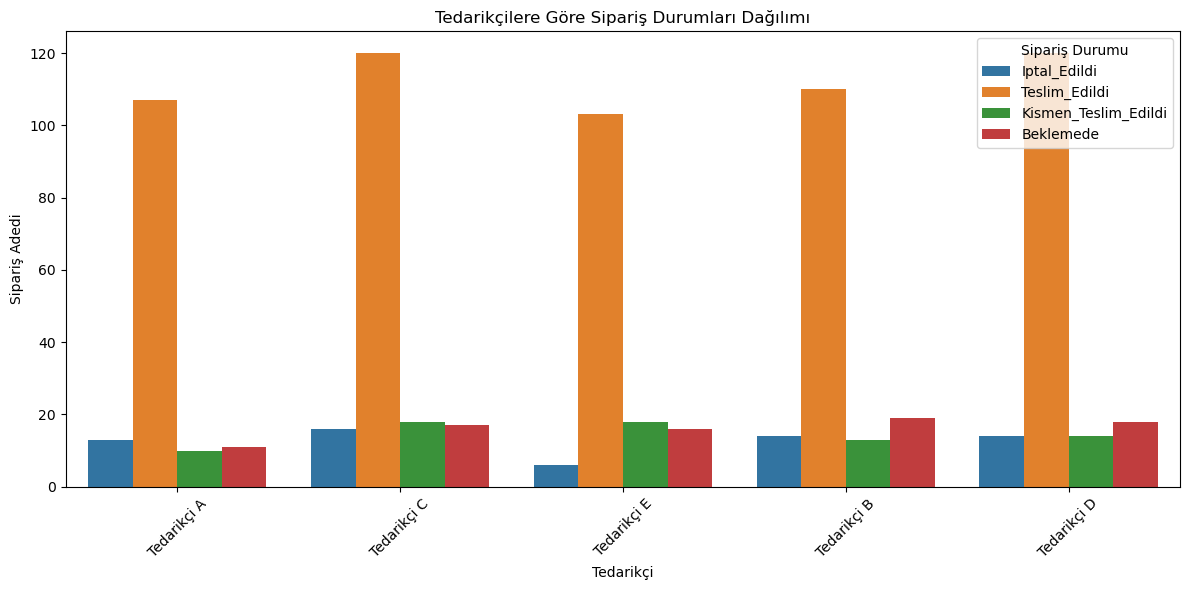

In [43]:
# A. Tedarikçiye Göre Sipariş Durumlarının Histogramı (Countplot)
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='Tedarikci', hue='Siparis_Durumu')
plt.title('Tedarikçilere Göre Sipariş Durumları Dağılımı')
plt.xlabel('Tedarikçi')
plt.ylabel('Sipariş Adedi')
plt.xticks(rotation=45)
plt.legend(title='Sipariş Durumu')
plt.tight_layout()
plt.show()


In [44]:

# B. Uyum Skoruna Göre Sipariş Durumu Çapraz Tablosu (Groupby Analizi)
uyum_durum_analizi = df.groupby(['Uyum_Skoru', 'Siparis_Durumu']).size().unstack(fill_value=0)
print("--- Uyum Skoruna Göre Sipariş Durumları ---")
print(uyum_durum_analizi)



--- Uyum Skoruna Göre Sipariş Durumları ---
Siparis_Durumu  Beklemede  Iptal_Edildi  Kismen_Teslim_Edildi  Teslim_Edildi
Uyum_Skoru                                                                  
Uygun                  68            52                    56            464
Uygun_Degil            13            11                    17             96


In [46]:

# --- DIŞA AKTARMA (EXPORT) İŞLEMLERİ ---
#4. Tedarikçi ve Ürün Kategorisine Göre Gruplayıp Ortalama İndirim Oranlarını Bulma
indirim_ozet_tablo = df.groupby(['Tedarikci', 'Urun_Kategorisi'])['Indirim_Orani'].mean().reset_index()

# Bu özet tabloyu ayrı bir CSV dosyası olarak dışa aktarma
indirim_ozet_tablo.to_csv('tedarikci_kategori_indirim_oranlari.csv', index=False)
print("\n[INFO] İndirim oranları tablosu 'tedarikci_kategori_indirim_oranlari.csv' olarak dışa aktarıldı.")




[INFO] İndirim oranları tablosu 'tedarikci_kategori_indirim_oranlari.csv' olarak dışa aktarıldı.



--- Ürün Kategorisine Göre Sipariş ve Başarı Analizi ---
     Urun_Kategorisi  Toplam_Siparis_Adedi  Ortalama_Urun_Basari_Orani
0  Ambalaj_Paketleme                166876                    0.949475
1         Elektronik                164829                    0.941908
2           Hammadde                151252                    0.937279
3   MRO_Bakim_Onarim                187658                    0.946573
4   Ofis_Malzemeleri                179936                    0.936078


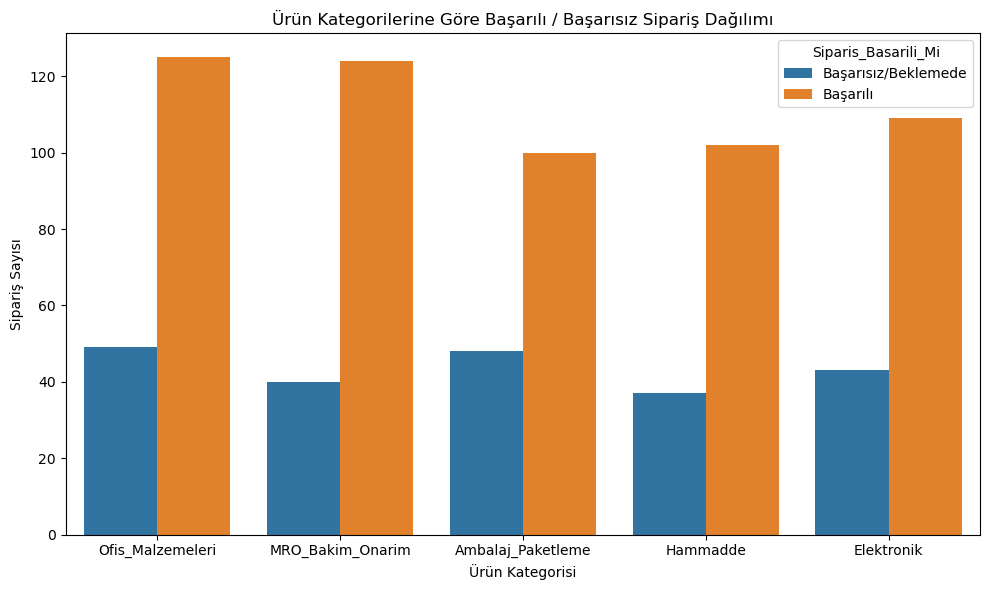

In [47]:
# 5. Ürün Kategorisine Göre Gruplayıp Sipariş Adedi ve Başarı Durumlarına Bakma
# Genel bir "Başarılı Sipariş" tanımı yapalım: Sipariş iptal edilmemişse ve Teslim edilmişse başarılı kabul edelim
df['Siparis_Basarili_Mi'] = df['Siparis_Durumu'].apply(lambda x: 'Başarılı' if x == 'Teslim_Edildi' else 'Başarısız/Beklemede')

urun_bazli_analiz = df.groupby('Urun_Kategorisi').agg(
    Toplam_Siparis_Adedi=('Miktar', 'sum'),
    Ortalama_Urun_Basari_Orani=('Basarili_Urun_Orani', 'mean')
).reset_index()

print("\n--- Ürün Kategorisine Göre Sipariş ve Başarı Analizi ---")
print(urun_bazli_analiz)

# Ürün kategorilerine göre Başarılı/Başarısız sipariş sayılarının görselleştirilmesi
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Urun_Kategorisi', hue='Siparis_Basarili_Mi')
plt.title('Ürün Kategorilerine Göre Başarılı / Başarısız Sipariş Dağılımı')
plt.xlabel('Ürün Kategorisi')
plt.ylabel('Sipariş Sayısı')
plt.tight_layout()
plt.show()

In [48]:
df.to_csv("2_procurement_kpı_TR.csv", encoding="utf-8", index=False)